# Prediction and Evaluation for 2026

The model trained on the 2020 scenes is applied to the Sentinel-2 scene of 2026-10-06 and compared with labels drawn by hand on that scene. Neither the scene nor its labels were used for training, so the test is independent in time. It is not fully independent in space: part of the park already existed in 2020 and was seen during training. The evaluation therefore also reports the accuracy on the installations built after 2020 separately.

Steps: prepare the scene, predict, evaluate against the labels, map the errors, report the area change since 2020, and export the result as polygons.

## Setup

In [16]:
import sys
from pathlib import Path

import geoai
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterio.features import rasterize

sys.path.append("../scripts")
from preprocessing import BASELINE_OFFSET, scale_to_byte

BASE_DIR = Path().resolve().parent if Path().resolve().name == "notebooks" else Path().resolve()
DATA_DIR = BASE_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
SCALED_DIR = DATA_DIR / "processed" / "scaled"
MODEL_DIR = BASE_DIR / "models"
PREDICTIONS_DIR = BASE_DIR / "results" / "predictions"
EVALUATION_DIR = BASE_DIR / "results" / "evaluation"
FIGURES_DIR = BASE_DIR / "results" / "figures"

SCENE_DAY = "2026-10-06"
FIRST_DAY = "2020-12-23"   # last hand-labelled scene of 2020, used for the area change

MODEL_FILE = "talatan_unet.pth"   # U-Net, ResNet34, four bands
NUM_CHANNELS = 4
MIN_AREA_M2 = 10_000       # smallest polygon kept in the vector output (1 ha)

raw_scene = RAW_DIR / "raster" / "sentinel2" / f"talatan_{SCENE_DAY}.tif"
scene = SCALED_DIR / f"talatan_{SCENE_DAY}_scaled.tif"
mask_path = PREDICTIONS_DIR / f"prediction_{SCENE_DAY}.tif"
probability_path = PREDICTIONS_DIR / f"probability_{SCENE_DAY}.tif"

for folder in (SCALED_DIR, PREDICTIONS_DIR, EVALUATION_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)


## Scene Preparation

Two corrections are applied before the scene reaches the model, both in `scripts/preprocessing.py`:

- Since processing baseline 04.00 (January 2022), Sentinel-2 Level-2A reflectance carries an offset of 1000. The 2026 scene is about 1000 higher than the 2020 scenes the model was trained on, so the offset is subtracted.
- Reflectance is then mapped from 0-4000 to 0-255, exactly as for the training tiles in notebook 02, because geoai divides every input image by 255.

In [17]:
scale_to_byte(raw_scene, scene, offset=BASELINE_OFFSET)

with rasterio.open(raw_scene) as src:
    before = [int(np.median(src.read(band))) for band in range(1, src.count + 1)]
with rasterio.open(scene) as src:
    after = [int(np.median(src.read(band))) for band in range(1, src.count + 1)]

print("Median reflectance per band:", before)
print("Median after scaling (0-255):", after)


Median reflectance per band: [1851, 2192, 2438, 3146]
Median after scaling (0-255): [54, 76, 92, 137]


## Prediction

The scene is predicted with a sliding window of 384 pixels and 50% overlap, which reduces artefacts at the window borders. The class mask and the probability map are written to `results/predictions/`.

In [18]:
geoai.semantic_segmentation(
    input_path=str(scene),
    output_path=str(mask_path),
    model_path=str(MODEL_DIR / MODEL_FILE),
    probability_path=str(probability_path),
    architecture="unet",
    encoder_name="resnet34",
    num_channels=NUM_CHANNELS,
    num_classes=2,
    window_size=384,
    overlap=192,
    batch_size=4,
)

with rasterio.open(mask_path) as src:
    predicted = src.read(1) == 1
    grid_shape, grid_transform, grid_crs = src.shape, src.transform, src.crs
    pixel_area = abs(src.transform.a * src.transform.e)

print(f"Predicted PV area: {predicted.sum() * pixel_area / 1e6:.1f} km²")


  0%|          | 0/525 [00:00<?, ?it/s]

Predicted PV area: 341.2 km²


## Evaluation

The prediction is compared with the hand labels of the same scene. They follow the same rule as the 2020 labels: the connected area of a plant counts as PV, internal tracks and gaps below roughly 50 m are included, larger open areas are left out.

In [19]:
def label_mask(day):
    """Rasterise the hand labels of one day on the prediction grid."""
    polygons = gpd.read_file(RAW_DIR / "vectors" / f"own_labels_{day}.shp").to_crs(grid_crs)
    polygons = polygons[polygons.geometry.notna() & ~polygons.geometry.is_empty]
    polygons["geometry"] = polygons.geometry.make_valid()
    polygons = polygons.explode(index_parts=False)
    polygons = polygons[(polygons.geom_type == "Polygon") & (polygons.area > 0)]
    return rasterize(polygons.geometry, out_shape=grid_shape, transform=grid_transform,
                     fill=0, default_value=1, dtype="uint8").astype(bool)


truth = label_mask(SCENE_DAY)

# IoU and F1 from geoai
scores = geoai.calc_segmentation_metrics(truth.astype("uint8"), predicted.astype("uint8"))

# geoai has no function for precision and recall, so these two are counted here
true_positive = int((predicted & truth).sum())
false_positive = int((predicted & ~truth).sum())
false_negative = int((~predicted & truth).sum())

metrics = pd.DataFrame([{
    "IoU": float(scores["iou"]),
    "F1": float(scores["f1"]),
    "precision": true_positive / (true_positive + false_positive),
    "recall": true_positive / (true_positive + false_negative),
    "predicted_km2": predicted.sum() * pixel_area / 1e6,
    "labelled_km2": truth.sum() * pixel_area / 1e6,
}], index=[SCENE_DAY]).round(3)

metrics.to_csv(EVALUATION_DIR / f"metrics_{SCENE_DAY}.csv")
metrics


,IoU,F1,precision,recall,predicted_km2,labelled_km2
2026-10-06,0.852,0.92,0.92,0.92,341.16,340.908


### Seen and Unseen Installations

About 40 % of the labelled PV area of 2026 lies on plants that already existed in 2020 and were part of the training scenes. On those, the model mainly recognises what it has seen. The score on the area built after 2020 measures how well it transfers to new plants. Pixels outside the part under evaluation are set to 0 in both masks, so they drop out of IoU and F1.

In [20]:
old = label_mask(FIRST_DAY)   # hand labels of 2020-12-23: PV seen during training
parts = {"built by 2020 (seen)": old, "built after 2020 (unseen)": ~old}

rows = []
for name, region in parts.items():
    part_scores = geoai.calc_segmentation_metrics(
        np.where(region, truth, 0).astype("uint8"),
        np.where(region, predicted, 0).astype("uint8"),
    )
    rows.append({
        "part": name,
        "share_of_labelled_area": (truth & region).sum() / truth.sum(),
        "IoU": float(part_scores["iou"]),
        "F1": float(part_scores["f1"]),
    })
rows.append({"part": "whole scene", "share_of_labelled_area": 1.0,
             "IoU": metrics["IoU"].iloc[0], "F1": metrics["F1"].iloc[0]})

split = pd.DataFrame(rows).set_index("part").round(3)
split.to_csv(EVALUATION_DIR / f"metrics_split_{SCENE_DAY}.csv")

for name, row in split.iterrows():
    print(f"{name:26s} {row['share_of_labelled_area'] * 100:4.0f} % of area | IoU {row['IoU']:.3f} | F1 {row['F1']:.3f}")

built by 2020 (seen)         42 % of area | IoU 0.954 | F1 0.976
built after 2020 (unseen)    58 % of area | IoU 0.786 | F1 0.880
whole scene                 100 % of area | IoU 0.852 | F1 0.920


### Error Map

Where the prediction agrees with the labels, where it predicts PV that is not labelled, and where it misses labelled PV.

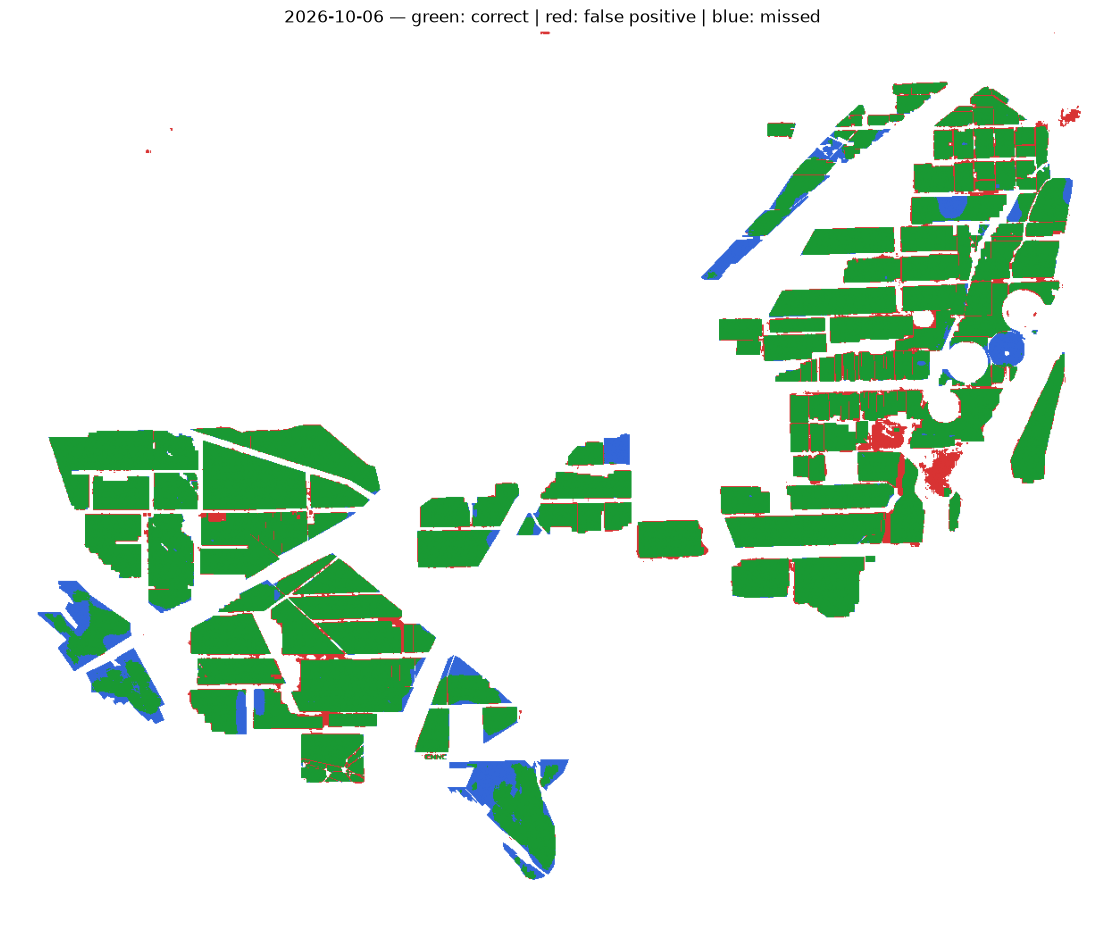

In [21]:
F = 4   # downsampling for display only

small_predicted, small_truth = predicted[::F, ::F], truth[::F, ::F]

errors = np.ones((*small_truth.shape, 3))
errors[small_truth & small_predicted] = [0.10, 0.60, 0.20]   # correct
errors[small_predicted & ~small_truth] = [0.85, 0.20, 0.20]  # predicted but not labelled
errors[small_truth & ~small_predicted] = [0.20, 0.40, 0.85]  # labelled but not predicted

plt.figure(figsize=(14, 12))
plt.imshow(errors)
plt.title(f"{SCENE_DAY} — green: correct | red: false positive | blue: missed")
plt.axis("off")
plt.savefig(FIGURES_DIR / f"evaluation_{SCENE_DAY}.png", dpi=150, bbox_inches="tight")
plt.show()


## Area Change 2020 to 2026

Both years are mapped by hand with the same rule, so this difference describes the growth of the solar park independently of the model.

In [22]:
areas_by_hand = {}
for day in (FIRST_DAY, SCENE_DAY):
    polygons = gpd.read_file(RAW_DIR / "vectors" / f"own_labels_{day}.shp").to_crs(grid_crs)
    polygons["geometry"] = polygons.geometry.make_valid()
    areas_by_hand[day] = polygons.union_all().area / 1e6

growth = areas_by_hand[SCENE_DAY] - areas_by_hand[FIRST_DAY]
years = (pd.Timestamp(SCENE_DAY) - pd.Timestamp(FIRST_DAY)).days / 365.25

print(f"{FIRST_DAY}: {areas_by_hand[FIRST_DAY]:6.1f} km²")
print(f"{SCENE_DAY}: {areas_by_hand[SCENE_DAY]:6.1f} km²")
print(f"growth:     {growth:6.1f} km² (+{growth / areas_by_hand[FIRST_DAY] * 100:.0f} % in {years:.1f} years)")


2020-12-23:  144.8 km²
2026-10-06:  340.9 km²
growth:      196.1 km² (+135 % in 5.8 years)


## Vector Output

The mask is converted to polygons. Polygons below 1 ha are dropped: that is the size of the smallest plant in the hand labels, and it removes isolated groups of pixels.

In [23]:
# Mask to polygons with geoai; polygons smaller than MIN_AREA_M2 are dropped
filtered = geoai.raster_to_vector(
    str(mask_path),
    output_path=str(PREDICTIONS_DIR / f"prediction_{SCENE_DAY}.gpkg"),
    threshold=0,
    min_area=MIN_AREA_M2,
    output_format="gpkg",
)

print(f"{len(filtered)} polygons of at least {MIN_AREA_M2 / 1e4:.0f} ha")
print(f"{filtered.area.sum() / 1e6:.1f} km² remaining")

geoai.create_split_map(
    left_layer=filtered,
    right_layer=str(raw_scene),
    left_args={"style": {"color": "red", "fillOpacity": 0.3}},
    right_args={"indexes": [3, 2, 1], "vmin": 1000, "vmax": 4000},
    basemap=str(raw_scene),
)


72 polygons of at least 1 ha
340.9 km² remaining


Map(center=[36.0500325, 100.39970349999999], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_…

## Probability Map

Band 2 of the probability map holds the probability of the PV class, band 1 the background. Values in the middle of the range mark areas the model is unsure about, mostly the edges of the plants.

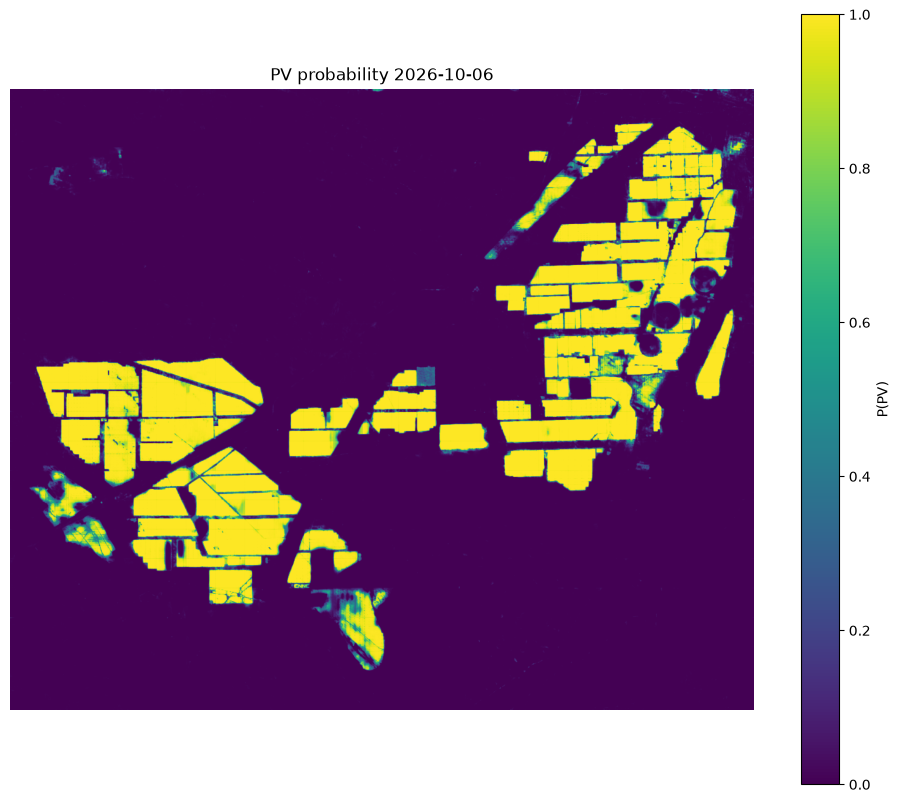

In [24]:
with rasterio.open(probability_path) as src:
    probability = src.read(2, out_shape=(src.height // F, src.width // F))

plt.figure(figsize=(12, 10))
plt.imshow(probability, cmap="viridis", vmin=0, vmax=1)
plt.colorbar(label="P(PV)")
plt.title(f"PV probability {SCENE_DAY}")
plt.axis("off")
plt.savefig(FIGURES_DIR / f"probability_{SCENE_DAY}.png", dpi=150, bbox_inches="tight")
plt.show()
